# 02 · Major-outage classifier

**Lights Out: Predicting Storm-Driven Power Outages and Recovery Across U.S. Counties**

Second step of our Option A analysis. The question: **when a storm hits a county, will more than 10% of its
customers lose power at the peak?** (`peak_share_out > 0.10`, the *major outage* label defined in
`01_eda.ipynb`).

Plan:

1. Build the modelling table and the label.
2. Choose features that are known **before or when the storm hits** (no leakage).
3. Decide how to evaluate: cross-validation **split by storm**, and why a random split is misleading.
4. Start from very simple baselines, then compare five scikit-learn models.
5. Tune the two best models a little, then test once on storms the models have never seen.
6. Look at what the model relies on.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

DATA = Path('..') / 'data'
SEED = 0
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (9, 4)

## 1. Modelling table and label

We start from `utility_by_county.csv` (one row per storm and county, with the reported outages) and add:

- from `storms.csv`: storm type (`kind`), year and month (landfall date, or first impact date);
- from `county_summary.csv`: whether the county is inside the NHC 34-knot wind radius, and the median
  night-light radiance **before** the storm (`baseline_radiance`, a rough proxy for how urban the county is).

As seen in `01_eda.ipynb`, rows with `reason != 'ok'` have no outage data, and `peak_share_out` is empty for
246 rows where more customers were reported out than the estimated customer count. Both are dropped.

In [2]:
storms = pd.read_csv(DATA / 'storms.csv')
utility = pd.read_csv(DATA / 'utility_by_county.csv', low_memory=False)
county = pd.read_csv(DATA / 'county_summary.csv', low_memory=False,
                     usecols=['event_id', 'geoid', 'in_nhc_wind_radius', 'baseline_radiance', 'outage_min_ratio'])

storms['date'] = pd.to_datetime(storms['landfall'].fillna(storms['first_impact_date']), errors='coerce')
storms['year'] = storms['date'].dt.year
storms['month'] = storms['date'].dt.month

df = (utility.merge(storms[['event_id', 'name', 'kind', 'year', 'month']], on='event_id', how='left')
             .merge(county, on=['event_id', 'geoid'], how='left'))
print('rows after the joins:', len(df), '(same as utility_by_county:', len(utility), ')')

df = df[(df['reason'] == 'ok') & df['peak_share_out'].notna()].copy()
df['major_outage'] = (df['peak_share_out'] > 0.10).astype(int)
print(f"usable rows: {len(df):,} from {df['event_id'].nunique()} storms")
print(f"major outages: {df['major_outage'].mean():.1%}")

rows after the joins: 11686 (same as utility_by_county: 11686 )
usable rows: 9,989 from 462 storms
major outages: 49.6%


## 2. Features

A useful model must work **at the time of the storm**, before the utilities report anything. So we only keep
information that is known before or when the storm hits:

| Feature | Type | Source |
|---|---|---|
| `kind` (storm type) | categorical | storms.csv |
| `state` | categorical | utility_by_county.csv |
| `wind_radius` (inside / outside the NHC wind radius, or unknown) | categorical | county_summary.csv |
| `year`, `month` | numeric | storms.csv |
| `log_customers` = log(1 + `customers_total`), county size | numeric | utility_by_county.csv |
| `log_baseline` = log(1 + `baseline_radiance`), pre-storm night light | numeric | county_summary.csv |

Everything measured **after** the storm is left out on purpose: `peak_customers_out`, `customer_hours_out`,
the restoration times, and the night-light drop (`outage_min_ratio`). They would leak the answer, or describe the
outage instead of predicting it. The night-light drop is only used as a separate baseline in section 4.

The wind radius only exists for the Atlantic storms covered by HURDAT2. Elsewhere it is empty, and empty does
**not** mean outside (see `data/DATA_DICTIONARY.md`), so we keep it as a third category, `unknown`.

In [3]:
df['log_customers'] = np.log1p(df['customers_total'])
df['log_baseline'] = np.log1p(df['baseline_radiance'])
df['wind_radius'] = (df['in_nhc_wind_radius'].astype('string').str.lower()
                       .map({'true': 'inside', 'false': 'outside'}).fillna('unknown'))

CAT = ['kind', 'state', 'wind_radius']
NUM = ['year', 'month', 'log_customers', 'log_baseline']
X = df[CAT + NUM]
y = df['major_outage'].to_numpy()
groups = df['event_id'].to_numpy()

print(df['wind_radius'].value_counts().to_string(), end='\n\n')
print('missing values per feature:')
print(X.isna().sum().to_string())

wind_radius
unknown    6228
outside    2082
inside     1679

missing values per feature:
kind             0
state            0
wind_radius      0
year             0
month            0
log_customers    0
log_baseline     0


## 3. How to evaluate: split by storm

All counties hit by the same storm share the same weather, the same date and often the same utility. If counties
of one storm end up both in the training set and in the test set, the model can recognise the storm instead of
learning something general. This is **leakage**, and it makes the score look better than it really is.

So every evaluation below uses `GroupKFold` with the storm (`event_id`) as the group: a storm is either fully in the
training folds or fully in the test fold. The metric is the **ROC AUC** (0.5 = coin flip, 1 = perfect), which
does not depend on a decision threshold. The two classes have similar sizes (about 50/50), so accuracy is also
meaningful, and we report it at the end.

We first keep 20% of the storms aside as a **final test set**, used only once in section 6.

In [4]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
g_train = groups[train_idx]

print(f'train: {len(train_idx):,} rows, {len(set(g_train))} storms, {y_train.mean():.1%} major')
print(f'test : {len(test_idx):,} rows, {len(set(groups[test_idx]))} storms, {y_test.mean():.1%} major')
print('storms in both sets:', len(set(g_train) & set(groups[test_idx])))

cv = GroupKFold(n_splits=5)

train: 7,998 rows, 369 storms, 50.0% major
test : 1,991 rows, 93 storms, 47.8% major
storms in both sets: 0


## 4. Simple baselines

Before any machine learning, three very simple predictors tell us what "good" means:

1. **Constant**: always predict the same thing. AUC 0.5 by definition.
2. **Storm-type lookup table**: predict the share of major outages seen for that storm type in the training folds.
3. **Night light only**: no training at all, just use how dark the county got after the storm
   (`outage_min_ratio`, lower = darker). This is the question from our proposal: can satellites alone detect an outage?

In [5]:
def lookup_auc(X_, y_, g_):
    scores = []
    for tr, te in cv.split(X_, y_, g_):
        rate = pd.Series(y_[tr]).groupby(X_['kind'].to_numpy()[tr]).mean()
        pred = pd.Series(X_['kind'].to_numpy()[te]).map(rate).fillna(y_[tr].mean())
        scores.append(roc_auc_score(y_[te], pred))
    return np.array(scores)

nl = df.iloc[train_idx]['outage_min_ratio']
has_nl = nl.notna().to_numpy()

baselines = {
    'Constant': np.array([0.5]),
    'Storm-type lookup table': lookup_auc(X_train, y_train, g_train),
    'Night light only (no model)': np.array([roc_auc_score(y_train[has_nl], -nl[has_nl])]),
}
for name, s in baselines.items():
    print(f'{name:30s} AUC {s.mean():.3f}')
print(f'\n(night light exists for {has_nl.sum():,} of {len(has_nl):,} training rows)')

Constant                       AUC 0.500
Storm-type lookup table        AUC 0.607
Night light only (no model)    AUC 0.563

(night light exists for 5,860 of 7,998 training rows)


The night-light signal is weak, close to the AUC of 0.52 to 0.57 reported by the dataset authors
(`data/validation_pooled.csv`). Clouds, generators that switch the lights back on before the grid, and destroyed
buildings that stay dark all blur the signal (`data/LIMITS.md`). The storm type alone does a bit better.

## 5. Comparing five models

We compare five classic scikit-learn classifiers, from the simplest to the strongest on tabular data:

| Model | Why we try it |
|---|---|
| Logistic regression | Linear baseline promised in our proposal, readable coefficients |
| Gaussian Naive Bayes | Very fast, but assumes the features are independent |
| Decision tree (depth 5) | Can be drawn and explained |
| Random forest | Many trees on random subsets, robust with little tuning |
| Gradient boosting (`HistGradientBoostingClassifier`) | Trees built one after the other to fix the previous errors, the usual best choice for tables |

Linear models and Naive Bayes need numbers, so categories are **one-hot encoded** and numeric features are
**scaled**. There are no missing values in these rows (see the check above), but an imputer (median of the
training folds) is kept in the pipeline so the model would not break on a county without baseline nights.
Gradient boosting handles categories and missing values natively, so it gets an ordinal
encoding instead. Every transformation is inside a `Pipeline`, so it is learned on the training folds only.

In [6]:
def onehot(model, scale=True):
    num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()) if scale else SimpleImputer(strategy='median')
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), CAT),
        ('num', num, NUM)])
    return make_pipeline(pre, model)

def ordinal(model):
    pre = ColumnTransformer([
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1), CAT),
        ('num', 'passthrough', NUM)])
    return make_pipeline(pre, model)

models = {
    'Logistic regression': onehot(LogisticRegression(max_iter=2000)),
    'Naive Bayes': onehot(GaussianNB()),
    'Decision tree (depth 5)': onehot(DecisionTreeClassifier(max_depth=5, random_state=SEED), scale=False),
    'Random forest': onehot(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED), scale=False),
    'Gradient boosting': ordinal(HistGradientBoostingClassifier(categorical_features=[0, 1, 2], random_state=SEED)),
}

scores = dict(baselines)
for name, model in models.items():
    scores[name] = cross_val_score(model, X_train, y_train, groups=g_train, cv=cv, scoring='roc_auc', n_jobs=-1)

table = pd.DataFrame({'mean AUC': {k: v.mean() for k, v in scores.items()},
                      'std': {k: v.std() for k, v in scores.items()}}).sort_values('mean AUC')
table.round(3)

,mean AUC,std
Constant,0.500,0.000
Night light only (no model),0.563,0.000
Naive Bayes,0.603,0.048
Storm-type lookup table,0.607,0.070
Decision tree (depth 5),0.678,0.044
Gradient boosting,0.698,0.033
Logistic regression,0.706,0.027
Random forest,0.720,0.030


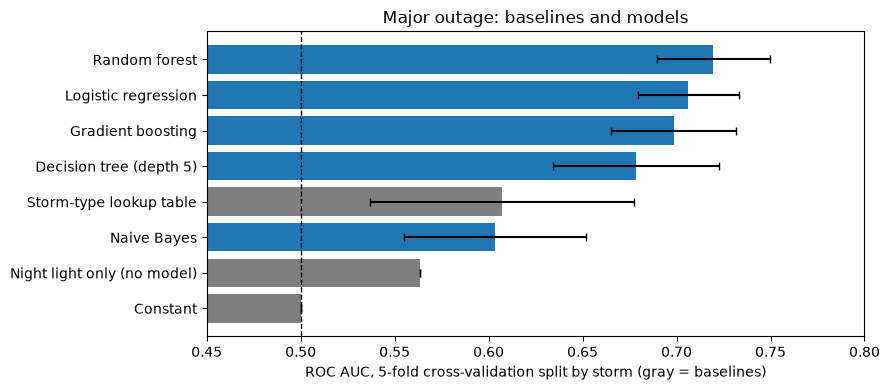

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = ['tab:blue' if k in models else 'tab:gray' for k in table.index]
ax.barh(table.index, table['mean AUC'], xerr=table['std'], color=colors, capsize=3)
ax.axvline(0.5, color='black', ls='--', lw=1)
ax.set_xlim(0.45, 0.8)
ax.set_xlabel('ROC AUC, 5-fold cross-validation split by storm (gray = baselines)')
ax.set_title('Major outage: baselines and models')
plt.tight_layout(); plt.show()

### Why the split matters

Same gradient boosting model, two ways of cutting the training data into folds: by storm, or at random.

In [8]:
gb = models['Gradient boosting']
by_storm = scores['Gradient boosting']
random_split = cross_val_score(gb, X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED),
                               scoring='roc_auc', n_jobs=-1)
print(f'split by storm : AUC {by_storm.mean():.3f}')
print(f'random split   : AUC {random_split.mean():.3f}  <- too optimistic')

split by storm : AUC 0.698
random split   : AUC 0.793  <- too optimistic


The random split gives a clearly higher score, but this score would not hold for a new storm: the model has
already seen other counties of the same storm. From now on we only trust the split by storm.

## 6. A little tuning, then the final test

Random forest is the best model, and logistic regression and gradient boosting are close behind. The two tree
ensembles have settings that change their behaviour a lot (tree size, learning rate, regularisation), so we tune
those two. We try a few settings for each, still with the split by storm on the training storms only. The grids are small on purpose: the goal is to show the procedure, not to squeeze the last point.

In [9]:
from sklearn.model_selection import GridSearchCV

searches = {
    'Random forest': GridSearchCV(
        onehot(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), scale=False),
        {'randomforestclassifier__min_samples_leaf': [1, 5, 20],
         'randomforestclassifier__max_features': ['sqrt', 0.5]},
        cv=cv, scoring='roc_auc', n_jobs=-1),
    'Gradient boosting': GridSearchCV(
        ordinal(HistGradientBoostingClassifier(categorical_features=[0, 1, 2], random_state=SEED)),
        {'histgradientboostingclassifier__learning_rate': [0.03, 0.1],
         'histgradientboostingclassifier__max_leaf_nodes': [15, 31],
         'histgradientboostingclassifier__l2_regularization': [0.0, 1.0]},
        cv=cv, scoring='roc_auc', n_jobs=-1),
}
for name, search in searches.items():
    search.fit(X_train, y_train, groups=g_train)
    print(f'{name:18s} best CV AUC {search.best_score_:.3f} with {search.best_params_}')

Random forest      best CV AUC 0.721 with {'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 20}


Gradient boosting  best CV AUC 0.706 with {'histgradientboostingclassifier__l2_regularization': 0.0, 'histgradientboostingclassifier__learning_rate': 0.1, 'histgradientboostingclassifier__max_leaf_nodes': 15}


We keep the model with the best cross-validated AUC, refit it on all training storms (`GridSearchCV` does this
automatically) and evaluate it **once** on the 20% of storms kept aside since section 3.

In [10]:
best_name = max(searches, key=lambda k: searches[k].best_score_)
best = searches[best_name].best_estimator_
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f'final model: {best_name}')
print(f'test AUC      : {roc_auc_score(y_test, proba):.3f}')
print(f'test accuracy : {accuracy_score(y_test, pred):.3f}  (always predicting the majority class: {max(y_test.mean(), 1 - y_test.mean()):.3f})')
print(f'precision     : {precision_score(y_test, pred):.3f}')
print(f'recall        : {recall_score(y_test, pred):.3f}')
print(f'F1            : {f1_score(y_test, pred):.3f}')

final model: Random forest
test AUC      : 0.707
test accuracy : 0.669  (always predicting the majority class: 0.522)
precision     : 0.638
recall        : 0.707
F1            : 0.671


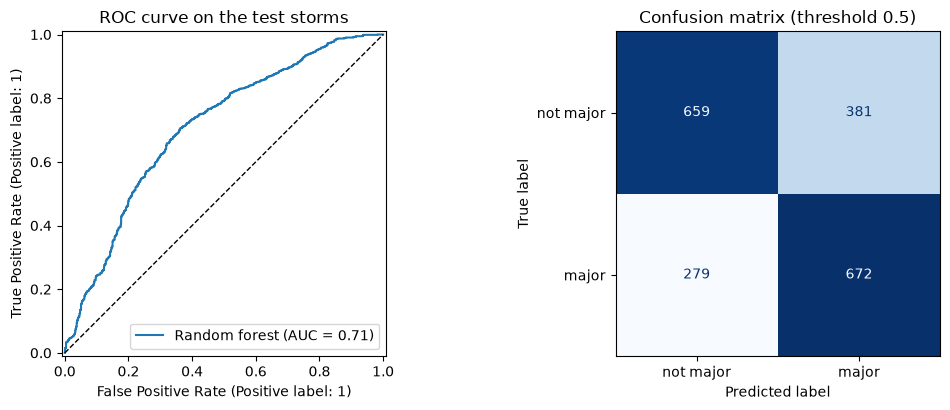

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], name=best_name)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('ROC curve on the test storms')
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['not major', 'major'], ax=axes[1],
                                        colorbar=False, cmap='Blues')
axes[1].set_title('Confusion matrix (threshold 0.5)')
plt.tight_layout(); plt.show()

## 7. What the model relies on

**Permutation importance**: shuffle one feature in the test set and measure how much the AUC drops. A big drop means
the model really uses that feature. It works on the original features (before one-hot encoding), so it is easy to read.

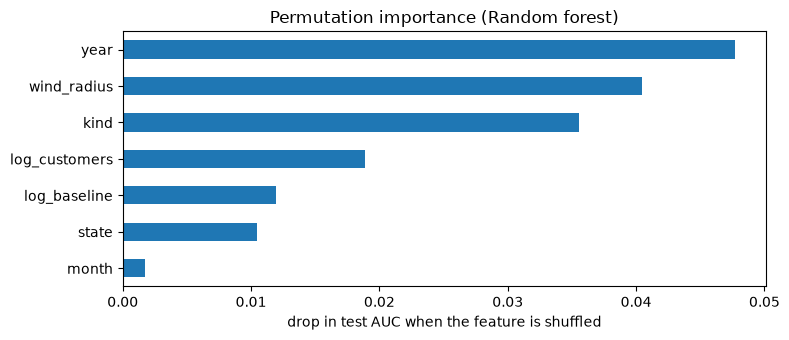

year             0.048
wind_radius      0.040
kind             0.036
log_customers    0.019
log_baseline     0.012
state            0.010
month            0.002
dtype: float64

In [12]:
imp = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
ax = imp.plot.barh(figsize=(8, 3.5))
ax.set_xlabel('drop in test AUC when the feature is shuffled')
ax.set_title(f'Permutation importance ({best_name})')
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3)

A shallow decision tree gives a picture of the same kind of rules. It is weaker than the ensemble, but it can be
read from top to bottom (depth 3 only, for readability).

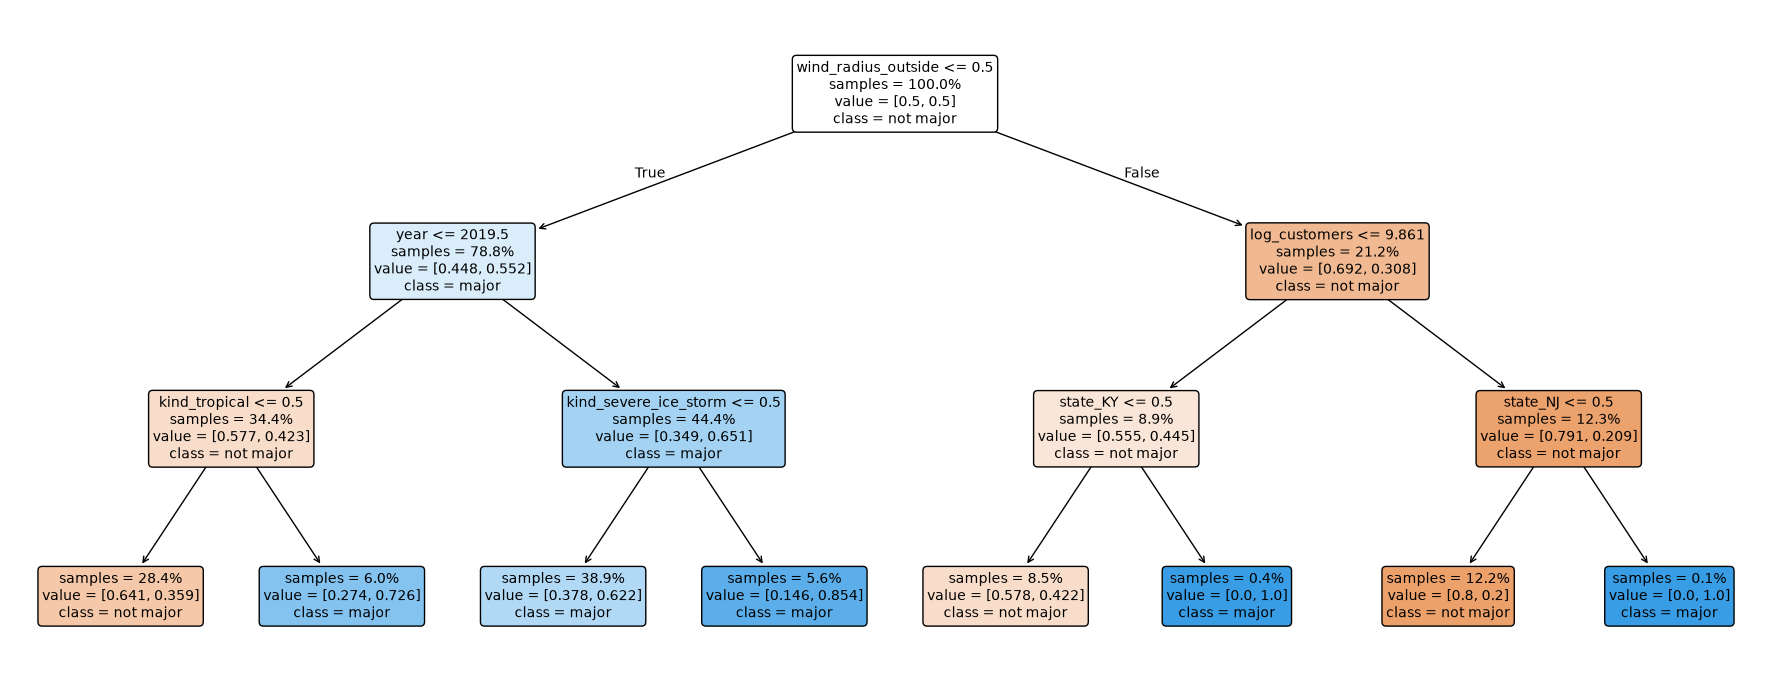

In [13]:
small_tree = onehot(DecisionTreeClassifier(max_depth=3, random_state=SEED), scale=False).fit(X_train, y_train)
names = small_tree[:-1].get_feature_names_out()
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(small_tree[-1], feature_names=[n.split('__', 1)[1] for n in names], class_names=['not major', 'major'],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=10, ax=ax)
plt.tight_layout(); plt.show()

## 8. Summary and next steps

In [14]:
summary = table['mean AUC'].round(3).to_dict()
print('Cross-validation split by storm (training storms):')
for k, v in sorted(summary.items(), key=lambda kv: kv[1]):
    print(f'  {k:30s} {v:.3f}')
print(f'\nFinal model ({best_name}) on unseen storms: AUC {roc_auc_score(y_test, proba):.3f}, accuracy {accuracy_score(y_test, pred):.3f}')

Cross-validation split by storm (training storms):
  Constant                       0.500
  Night light only (no model)    0.563
  Naive Bayes                    0.603
  Storm-type lookup table        0.607
  Decision tree (depth 5)        0.678
  Gradient boosting              0.698
  Logistic regression            0.706
  Random forest                  0.720

Final model (Random forest) on unseen storms: AUC 0.707, accuracy 0.669


- Night light alone barely beats a coin flip, as the dataset authors found.
- With a few features known at storm time, the best models (random forest, then logistic regression and gradient
  boosting) reach an AUC around 0.7 on storms they have never seen. This is better than every baseline, but far
  from perfect: county and storm descriptions only explain part of who loses power.
- The small tree splits first on the wind radius: counties known to be outside it rarely have a major outage.
- A random split would have overstated the score. Splitting by storm is necessary for an honest estimate.
- The wind radius is among the most useful features, but it only exists for Atlantic storms covered by HURDAT2.
  Adding real wind speed and pressure (`05_hurdat2_enrichment`) is the natural way to improve the model.

Next notebook: `03_regression`, the time needed to restore 90% of customers.